<a href="https://colab.research.google.com/github/alimasumajja/PM-turi4-clustering-AliMa-sumAjjawiyi/blob/main/PM_P9_ALI_MA'SUM_AJJAWIYI_2488010010.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
df = pd.read_csv('dataset_pelanggan.csv')
X_scaled = StandardScaler().fit_transform(df)


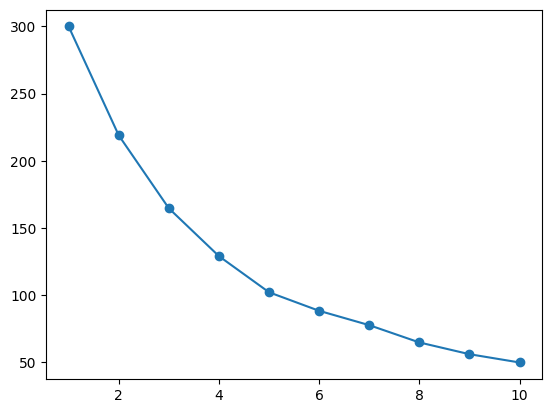

In [6]:
from sklearn.cluster import KMeans
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled); inertias.append(km.inertia_)
plt.plot(range(1,11), inertias, marker='o'); plt.show()


In [9]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts())


cluster
2    39
1    33
0    28
Name: count, dtype: int64


In [19]:
from sklearn.metrics import silhouette_score
labels_unscaled = kmeans.fit_predict(df)
print(silhouette_score(X_scaled, df['cluster']))
print(silhouette_score(df, labels_unscaled))


0.2689481956457897
0.592793600819906


In [11]:
profil = df.groupby('cluster')[['usia','pendapatan',
    'skor_belanja']].mean().round(1)
print(profil)   # beri nama tiap cluster berdasarkan profil


         usia  pendapatan  skor_belanja
cluster                                
0        38.7   7777040.5          19.2
1        46.1   8053856.6          77.6
2        38.1  16430973.6          44.2


In [12]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Melatih Model dan Menghitung Silhouette Score untuk K=3
kmeans_3 = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_3 = kmeans_3.fit_predict(X_scaled)
score_3 = silhouette_score(X_scaled, labels_3)

# 2. Melatih Model dan Menghitung Silhouette Score untuk K=5
kmeans_5 = KMeans(n_clusters=5, random_state=42, n_init=10)
labels_5 = kmeans_5.fit_predict(X_scaled)
score_5 = silhouette_score(X_scaled, labels_5)

# 3. Mencetak Perbandingan Hasil
print(f"Silhouette Score K=3: {score_3:.4f}")
print(f"Silhouette Score K=5: {score_5:.4f}")

Silhouette Score K=3: 0.2689
Silhouette Score K=5: 0.3367


**D. Latihan Mandiri**

6. Setelah menjalankan K-means dan membandingkan nilai K = 5 dan K = 3, nilai silhoutte score dengan K = 5 adalah 0,3367 dan nilai dari K = 3 adalah 0,2689. dari kedua nilai silhoutte tersebut nilai K = 5 memiliki nilai terbesar dibandingkan dengan K = 3

7. hasilnya menunjukan bahwa skor Silhouette memiliki kenaikan dari 0,2689 yang menggunakan scaling K = 3 menjadi 0,5927 tanpa menggunakan scaling K = 3. kesimpulannya tanpa menggunakan standarisasi scaling, sistem hanya membandingkan satu fitur untuk menghasilkan nilai silhouette. Jika hanya satu fitur yang dibandingkan nilai silhouette yang dihasilkan akan tidak sesuai

8. berikut ini merupakan scatter plot cluster pada fitur usia (x) vs skor_belanja (y).

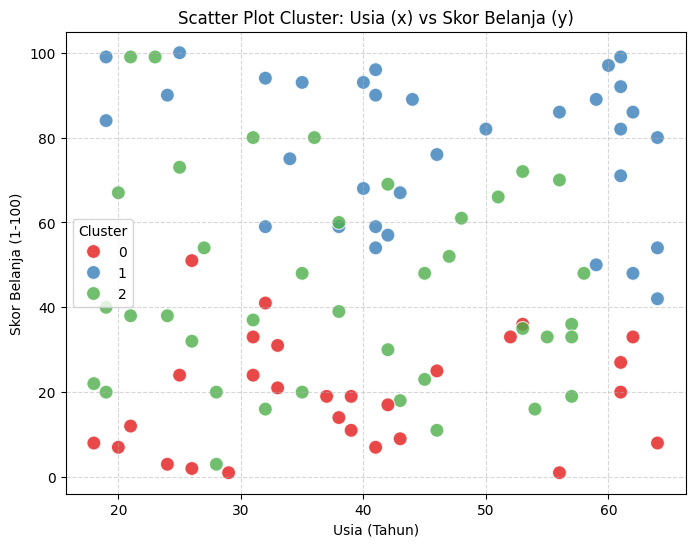

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x='usia',
    y='skor_belanja',
    hue='cluster',
    palette='Set1',
    s=100,
    alpha=0.8
)

plt.title('Scatter Plot Cluster: Usia (x) vs Skor Belanja (y)')
plt.xlabel('Usia (Tahun)')
plt.ylabel('Skor Belanja (1-100)')
plt.legend(title='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)

# Menampilkan grafik
plt.show()

**E. Refleksi**

9. K-mens menemukan kelompok dengan cara iteratif dimana menentukan nilai K atau jumlah dari cluster (pengelompokan). Kemudian data dikelompokkan berdasarkan nilai terdekat pada data yang terpilih sebagai cluster. kemudian menghitung nilai rata-rata dari setiap cluster. jika terdapat data baru maka akan dikelompokkan berdasarkan nilai terdekat dari nilai rata-rata cluster dan akan dihitung kembali nilai rata-rata disetiap cluster. langkah-langkah tersebut akan dilakukan secara berulang jika terdapat data baru.

10. karena pada metode Elbow ini mencari inertia yaitu nilai k (jumlah pengelompokan) yang optimal. Metode Elbow menunjukan siku pada K = 3 menandakan nilai dari K = 3 memberikan perbaikan paling kecil.

11. scaling sangat penting dalam k-means ini karena scaling merubah nilai data numerik dalam rentang tertentu untuk membantu proses pengelompokan yang sempurna. jika scaling dilewatkan pengelompokan data menjadi tidak sesuai atau menyesatkan
